
---
date: "2026-11-13"
date-modified: last-modified
format:
  html:
    toc: true
---


# Simulating Hawkes Processes

**Prerequisites:** [The Hawkes process](hawkes-process.ipynb) · [Thinning and superposition](point-processes-and-poisson-process.ipynb#thm-thinning) · [Conditional intensity](conditional-intensity-and-compensator.ipynb#prp-hazard-representation)

Simulation is how we compute what has no closed form (prediction intervals, the law of a maximum, bootstrap standard errors) and how we test estimators on data whose true parameters we know. There are three standard methods. The **cluster method** follows the branching picture, **Ogata's thinning** works for any intensity with a computable upper bound, and for the exponential kernel there is an **exact method** that needs no rejection at all.

## 1\. Simulation by the Cluster Representation

By the [cluster representation](hawkes-process.ipynb#thm-cluster-representation), a Hawkes process on $(0, T]$ is obtained by generating immigrants and then, generation by generation, the children of every point.

::: {.callout-note}
## Algorithm: immigration–birth simulation on $(0, T]$
Input: $\mu$, $\eta$, the delay density $g = \varphi/\eta$, the horizon $T$.

1. Draw the immigrants: $n_0 \sim \operatorname{Pois}(\mu T)$ points i.i.d. $\operatorname{Unif}(0, T)$. Put them in a queue.
2. While the queue is not empty, remove a point $s$; draw $K \sim \operatorname{Pois}(\eta)$ and delays $D_1, \dots, D_K$ i.i.d. with density $g$; add every child $s + D_j \le T$ to the output *and to the queue*.
3. Return all points, sorted.
:::

Correctness is the [cluster representation](hawkes-process.ipynb#thm-cluster-representation) together with the [branching structure](hawkes-process.ipynb#prp-branching-structure): the children of a point at $s$ form an inhomogeneous Poisson process with rate $\varphi(\cdot - s)$, which is the same as a $\operatorname{Pois}(\eta)$ number of i.i.d. delays with density $g$. Children born after $T$ can be dropped, because their own descendants are born even later. The cost is $O(n)$ for $n$ events, and the algorithm also returns the family tree.

::: {.callout-warning}
## Every point has children
Step 2 must put the children back into the queue. A version that only generates children of the immigrants simulates a different process, whose clusters have exactly two generations; its mean intensity is $\mu(1 + \eta)$ instead of $\mu/(1-\eta)$.
:::

## 2\. Ogata's Thinning Algorithm

Write $\tilde\lambda_s$ for the intensity at $s$ computed from the events found so far, as if no new event occurred. Thinning needs an upper bound for $\tilde\lambda$ over some time ahead.

::: {.callout-note}
## Algorithm: Ogata's modified thinning on $(0, T]$
Start with $t = 0$ and no events. Repeat:

1. choose a look-ahead $L > 0$ and a bound $M \ge \sup_{s \in (t, t + L]}\tilde\lambda_s$;
2. draw $E \sim \operatorname{Expo}(M)$; if $E > L$, set $t \leftarrow t + L$ and go to 1;
3. otherwise set $t \leftarrow t + E$; stop if $t > T$;
4. draw $U \sim \operatorname{Unif}(0, M)$; if $U \le \tilde\lambda_t$, record an event at $t$;
5. go to 1.

For a **nonincreasing kernel** $\varphi$, the intensity $\tilde\lambda$ is nonincreasing between events, so one can take $L = \infty$ and $M = \tilde\lambda_{t+}$, the current intensity just after time $t$ (including the jump of an event recorded at $t$).
:::

::: {#thm-ogata-thinning}
## Correctness of thinning
The points recorded by Ogata's algorithm form a point process with conditional intensity $\lambda$ (computed from the recorded points). In particular, with $\lambda_t = \mu + \sum_{T_i < t}\varphi(t - T_i)$ it produces a Hawkes process.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-ogata-thinning
Suppose the $k$-th event has been recorded at $T_k$ (or $k = 0$, $T_0 = 0$); then $\tilde\lambda_s$, $s > T_k$, is a deterministic function until the next record. By the [hazard representation](conditional-intensity-and-compensator.ipynb#prp-hazard-representation) it suffices to show that, given the past, the next recorded time $T_{k+1}$ satisfies $P(T_{k+1} > u) = \exp\big(-\int_{T_k}^u\tilde\lambda_s\,ds\big)$ for all $u > T_k$.

The algorithm proceeds through **rounds**: a round starts at a time $t$ with a bound $M$ valid on $(t, t+L]$, and ends at the first candidate or at $t + L$. The candidate times of a round are the first point of a Poisson process with rate $M$ on $(t, t+L]$ (exponential gap). If we imagined the round continuing, all its candidate points would form a homogeneous Poisson process with rate $M$ on $(t, t + L]$; because exponential gaps are memoryless, restarting a new round at a rejected candidate with a new bound and fresh randomness produces the same law of the future as continuing. By the [thinning theorem](point-processes-and-poisson-process.ipynb#thm-thinning), the accepted candidates of a round with $U \le \tilde\lambda$ form an inhomogeneous Poisson process with rate $\tilde\lambda \le M$ on that round's interval. Hence, for $u$ in a round $(t, t']$ that started with no acceptance so far,
$$
P(\text{no acceptance in } (t, u] \mid \text{no acceptance before } t) = \exp\Big(-\int_t^u\tilde\lambda_s\,ds\Big).
$$
The rounds use independent randomness, so multiplying these probabilities over the successive rounds between $T_k$ and $u$ gives $P(T_{k+1} > u) = \exp\big(-\int_{T_k}^u\tilde\lambda_s\,ds\big)$. $\blacksquare$
:::

The expected number of candidates is $E\int_0^T M_t\,dt$, so a tight bound matters. Each acceptance test evaluates $\tilde\lambda_t$, which costs $O(n)$ for a general kernel (a sum over past events) and $O(1)$ for the exponential kernel (by the [Markov recursion](hawkes-process.ipynb#prp-exponential-markov)); thinning is then $O(n^2)$, respectively $O(n)$. The same algorithm simulates multivariate and nonlinear Hawkes processes: bound the *total* intensity, and assign an accepted point to a component with probability proportional to its intensity.

::: {.callout-note}
## Intuition: rejection sampling with a falling ceiling
After an event the intensity is at a local peak, and with a decreasing kernel it can only fall until the next event. So the current value is a ceiling. Propose a time at the ceiling's rate; at that time, compare a uniform height with the true (lower) intensity; whether the candidate is accepted or not, lower the ceiling to the current intensity and continue.
:::

In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})
from la_manim import *

class OgataThinning(Scene):
    def construct(self):
        rng = np.random.default_rng(12)
        mu, alpha, beta, T = 0.6, 1.2, 1.5, 7.0
        ax = Axes(x_range=[0, T, 1], y_range=[0, 4, 1], x_length=8.4, y_length=3.0,
                  axis_config={"color": C_MUTED, "stroke_width": 1.6, "include_tip": False},
                  x_axis_config={"numbers_to_include": range(0, 8), "font_size": 22},
                  y_axis_config={"numbers_to_include": range(0, 5), "font_size": 22}).move_to([0.2, 0.05, 0])
        self.add(ax, caption(r"\text{accept } s \text{ if } U \le \lambda_s,\quad U \sim \mathrm{Unif}(0, M)", corner=UL, scale=0.62))
        ev, t = [], 0.0
        lam = lambda s: mu + sum(alpha * np.exp(-beta * (s - e)) for e in ev if e < s)
        lam_plus = lambda s: mu + sum(alpha * np.exp(-beta * (s - e)) for e in ev if e <= s)
        curve = VGroup()
        self.add(curve)
        while True:
            M = lam_plus(t)
            E = rng.exponential(1 / M)
            s = t + E
            end = min(s, T)
            ceil = DashedLine(ax.c2p(t, M), ax.c2p(end, M), color=C_RED, stroke_width=2.5)
            seg = ax.plot(lambda x: lam(x) if x > t + 1e-9 else lam_plus(t), x_range=[t, end, 0.01], color=C_BLUE, stroke_width=3)
            self.play(Create(ceil), Create(seg), run_time=0.45 + 0.25 * (end - t))
            curve.add(seg)
            if s > T:
                break
            u = rng.uniform(0, M)
            ok = u <= lam(s)
            dot = Dot(ax.c2p(s, u), radius=0.07, color=C_BLUE if ok else C_FAINT)
            self.play(FadeIn(dot, scale=1.6), run_time=0.3)
            if ok:
                ev.append(s)
                tick = Line(ax.c2p(s, 0), ax.c2p(s, 0.3), color=C_ORANGE, stroke_width=4)
                self.play(dot.animate.move_to(ax.c2p(s, 0.15)).set_color(C_ORANGE), FadeIn(tick), run_time=0.35)
                self.remove(dot)
                jump = Line(ax.c2p(s, lam(s)), ax.c2p(s, lam_plus(s)), color=C_BLUE, stroke_width=3)
                self.play(Create(jump), run_time=0.2); curve.add(jump)
            else:
                cross = Cross(dot, stroke_color=C_FAINT, stroke_width=3, scale_factor=1.6)
                self.play(FadeIn(cross), run_time=0.2)
            self.play(ceil.animate.set_opacity(0.45), run_time=0.15)
            t = s
        self.add(text_caption(r"dashed red: ceiling $M$ (reset after every candidate); grey: rejected", corner=DL, scale=0.55))
        self.wait(1.5)

# manim exports its own BLUE, RED, ...: restore the palette of the static figures
BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
show(OgataThinning)


## 3\. Exact Simulation for the Exponential Kernel

For $\varphi(t) = \alpha e^{-\beta t}$ the waiting time to the next event can be sampled directly. After an event at $T_k$, let $Y = \lambda_{T_k+} - \mu$ be the **excess intensity**. Until the next event,
$$
\tilde\lambda_{T_k + s} = \mu + Y e^{-\beta s}, \qquad s > 0 .
$$

::: {#prp-exact-exponential}
## Decomposition of the waiting time
Let $E_1 \sim \operatorname{Expo}(\mu)$ and, independently, let $E_2$ be a $(0, \infty]$-valued random variable with
$$
P(E_2 > s) = \exp\Big(-\frac{Y}{\beta}\big(1 - e^{-\beta s}\big)\Big), \qquad s \ge 0,
$$
so that $P(E_2 = \infty) = e^{-Y/\beta} > 0$. Then the next event time is distributed as $T_k + \min(E_1, E_2)$. With $U \sim \operatorname{Unif}(0, 1)$, $E_2$ can be sampled by inversion:
$$
D = 1 + \frac{\beta\log U}{Y}, \qquad E_2 = \begin{cases} -\dfrac{\log D}{\beta}, & D > 0, \\[1ex] \infty, & D \le 0 . \end{cases}
$$
After the event the excess becomes $Y e^{-\beta\min(E_1, E_2)} + \alpha$.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-exact-exponential
By the [hazard representation](conditional-intensity-and-compensator.ipynb#prp-hazard-representation), the waiting time $W = T_{k+1} - T_k$ has survival function
$$
P(W > s) = \exp\Big(-\int_0^s(\mu + Ye^{-\beta u})\,du\Big) = e^{-\mu s}\exp\Big(-\frac{Y}{\beta}(1 - e^{-\beta s})\Big) = P(E_1 > s)\,P(E_2 > s),
$$
and the product of the survival functions of independent variables is the survival function of their minimum. For the inversion, $P(E_2 > s) = U$ is solved by $1 - e^{-\beta s} = -\beta\log U/Y$, i.e. $e^{-\beta s} = D$, which has a solution $s \in (0, \infty)$ exactly when $0 < D < 1$; $D \le 0$ means $U \le e^{-Y/\beta}$, an event of probability $P(E_2 = \infty)$. Since $s \mapsto P(E_2 > s)$ is decreasing, $E_2$ obtained this way has the required law. The update of the excess is the [Markov recursion](hawkes-process.ipynb#prp-exponential-markov). $\blacksquare$
:::

::: {.callout-note}
## Intuition: two competing alarm clocks
The next event is either a new immigrant (clock $E_1$, rate $\mu$) or a descendant of the events so far (clock $E_2$, with a decaying rate $Ye^{-\beta s}$ whose total mass $Y/\beta$ is finite). The second clock may never ring: with probability $e^{-Y/\beta}$ the current excitation dies out without producing another event.
:::

::: {.callout-warning}
## Two pitfalls
Printed versions of this algorithm sometimes (i) take $\log D$ without checking $D > 0$, which fails exactly when the excitation dies out, and (ii) start from an excess of $\alpha$ at time $0$, which inserts a phantom event at $t = 0$. The correct initial excess is $\lambda_0 - \mu$ (zero for a process started at its baseline).
:::

::: {.callout-note}
## Algorithm: exact simulation, exponential kernel
Start with $t = 0$, $Y = \lambda_0 - \mu$. Repeat: draw $E_1$ and $E_2$ as in @prp-exact-exponential, set $w = \min(E_1, E_2)$ and $t \leftarrow t + w$; stop if $t > T$; record $t$ and set $Y \leftarrow Ye^{-\beta w} + \alpha$.
:::

## 4\. Starting in the Stationary Regime

All three algorithms start from an empty past, so the simulated process begins below its stationary level: the mean intensity rises from $\mu$ toward $\bar\lambda = \mu/(1-\eta)$ ([mean intensity](hawkes-process.ipynb#cor-exponential-mean)). To imitate a process that has been running forever, simulate on $(-B, T]$ and keep only the events in $(0, T]$ (**burn-in**). For the exponential kernel the transient decays like $e^{-(\beta - \alpha)t}$, so $B$ should be several multiples of $1/(\beta - \alpha)$, which is long near criticality. For power-law kernels the transient decays only polynomially and long burn-ins are needed.

## 5\. Simulation on Mock Data

We implement the three methods for $\mu = 1$, $\alpha = 1.5$, $\beta = 2$ ($\eta = 0.75$, $\bar\lambda = 4$) on $(0, 50]$, and compare the distribution of $N_T$ over $3000$ runs of each with the exact mean $E\,N_T = \bar\lambda T + (\mu - \bar\lambda)(1 - e^{-\kappa T})/\kappa$, $\kappa = \beta - \alpha$ (integrate the [mean-intensity formula](hawkes-process.ipynb#cor-exponential-mean)).

        cluster: mean N_T =  194.21  (exact 194.00),  sd =  54.4,  0.62 ms per path


 Ogata thinning: mean N_T =  195.66  (exact 194.00),  sd =  55.8,  0.17 ms per path


          exact: mean N_T =  193.18  (exact 194.00),  sd =  54.6,  0.19 ms per path
two-sample KS p-values: {'cluster vs exact': 0.779, 'Ogata thinning vs exact': 0.276}


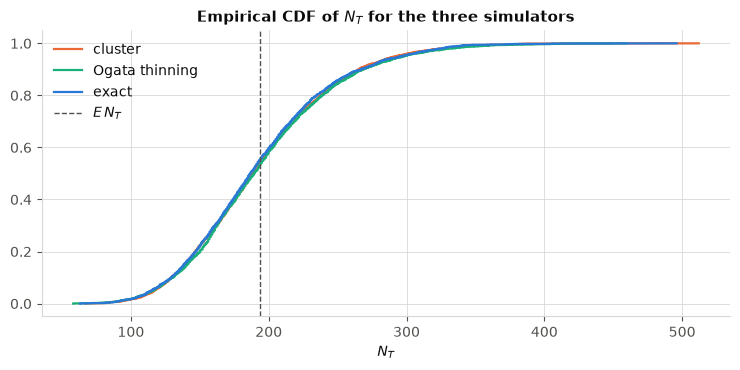

In [2]:

import math, time
from scipy import stats

def sim_cluster(mu, alpha, beta, T, rng):
    eta = alpha / beta
    queue = list(rng.uniform(0, T, rng.poisson(mu * T))); out = list(queue)
    while queue:
        s = queue.pop()
        kids = s + rng.exponential(1 / beta, rng.poisson(eta))
        kids = kids[kids <= T]
        queue.extend(kids); out.extend(kids)
    return np.sort(np.array(out))

def sim_ogata(mu, alpha, beta, T, rng):
    t, excess, ev = 0.0, 0.0, []                # excess = lambda_{t+} - mu, updated in O(1)
    while True:
        M = mu + excess                         # ceiling = current intensity (kernel is decreasing)
        w = rng.exponential(1 / M)
        t += w
        if t > T:
            return np.array(ev)
        excess *= math.exp(-beta * w)           # intensity at the candidate, before any jump
        if rng.random() * M <= mu + excess:
            ev.append(t); excess += alpha

def sim_exact(mu, alpha, beta, T, rng):
    t, excess, ev = 0.0, 0.0, []
    while True:
        e1 = rng.exponential(1 / mu); e2 = math.inf
        if excess > 0:
            D = 1 + beta * math.log(rng.random()) / excess
            if D > 0:
                e2 = -math.log(D) / beta
        w = min(e1, e2); t += w
        if t > T:
            return np.array(ev)
        excess = excess * math.exp(-beta * w) + alpha
        ev.append(t)

mu, alpha, beta, T = 1.0, 1.5, 2.0, 50.0
kap, lbar = beta - alpha, mu * beta / (beta - alpha)
EN = lbar * T + (mu - lbar) * (1 - np.exp(-kap * T)) / kap
rng = np.random.default_rng(0)
res = {}
for name, f in [("cluster", sim_cluster), ("Ogata thinning", sim_ogata), ("exact", sim_exact)]:
    t0 = time.perf_counter()
    res[name] = np.array([len(f(mu, alpha, beta, T, rng)) for _ in range(3000)])
    print(f"{name:>15}: mean N_T = {res[name].mean():7.2f}  (exact {EN:.2f}),  sd = {res[name].std():5.1f},"
          f"  {1e3 * (time.perf_counter() - t0) / 3000:.2f} ms per path")
print("two-sample KS p-values:", {f"{a} vs {b}": round(float(stats.ks_2samp(res[a], res[b]).pvalue), 3)
                                 for a, b in [("cluster", "exact"), ("Ogata thinning", "exact")]})

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for (name, n), c in zip(res.items(), [ORANGE, AQUA, BLUE]):
    x = np.sort(n); ax.step(x, np.arange(1, len(x) + 1) / len(x), color=c, lw=1.6, label=name)
ax.axvline(EN, color=MUTED, ls="--", lw=1, label=r"$E\,N_T$")
ax.set(title=r"Empirical CDF of $N_T$ for the three simulators", xlabel="$N_T$"); ax.legend()
plt.tight_layout(); plt.show()


**Time rescaling check.** For a long path from each simulator, the residual gaps $\int_{T_{k-1}}^{T_k}\lambda_u\,du$ computed with the *true* parameters must be i.i.d. $\operatorname{Expo}(1)$ ([time-rescaling theorem](conditional-intensity-and-compensator.ipynb#thm-time-rescaling)). The compensator increments follow from the [Markov recursion](hawkes-process.ipynb#prp-exponential-markov).

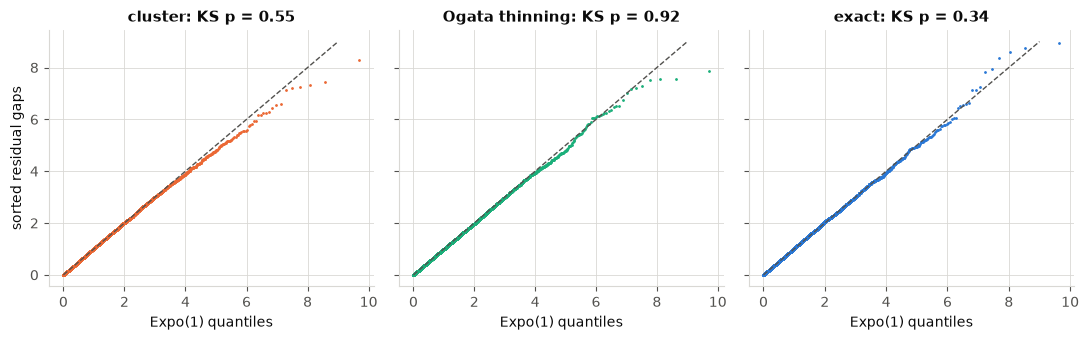

In [3]:

def residuals(ev, mu, alpha, beta):
    """Compensator increments between consecutive events (exponential kernel, lambda_0 = mu)."""
    r, excess, prev = np.empty(len(ev)), 0.0, 0.0
    for k, t in enumerate(ev):
        w = t - prev
        r[k] = mu * w + excess * (1 - math.exp(-beta * w)) / beta
        excess = excess * math.exp(-beta * w) + alpha; prev = t
    return r

fig, ax = plt.subplots(1, 3, figsize=(11, 3.5), sharey=True)
for a, (name, f), c in zip(ax, [("cluster", sim_cluster), ("Ogata thinning", sim_ogata), ("exact", sim_exact)], [ORANGE, AQUA, BLUE]):
    r = residuals(f(mu, alpha, beta, 2000.0, rng), mu, alpha, beta)
    q = (np.arange(1, len(r) + 1) - 0.5) / len(r)
    a.plot(-np.log(1 - q), np.sort(r), ".", ms=2, color=c); a.plot([0, 9], [0, 9], color=MUTED, ls="--", lw=1)
    a.set(title=f"{name}: KS p = {stats.kstest(r, 'expon').pvalue:.2f}", xlabel="Expo(1) quantiles")
ax[0].set_ylabel("sorted residual gaps")
plt.tight_layout(); plt.show()


**A power-law kernel by thinning.** For $\varphi(t) = K(t + c)^{-p}$ there is no Markov shortcut, so each acceptance test sums over all past events. With $c = 0.1$, $p = 1.6$, $\eta = 0.7$ and $\mu = 0.3$ (so $\bar\lambda = 1$) we compare the average of $N_t$ over $300$ paths with $\int_0^t m$, where $m$ solves the [renewal equation](hawkes-process.ipynb#thm-hawkes-mean) numerically. The slow approach to the stationary slope $\bar\lambda$ is the heavy tail at work.

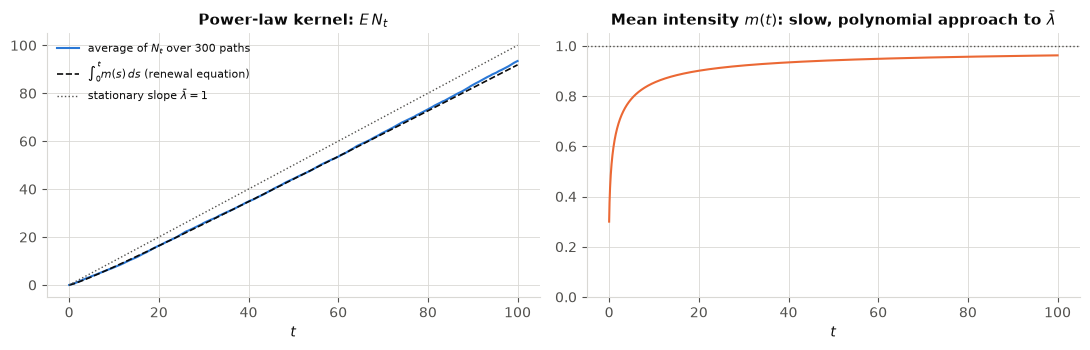

E N_T at T = 100: simulated 93.45 ± 1.74, renewal equation 91.85


In [4]:

c_, p_, eta_, mu_ = 0.1, 1.6, 0.7, 0.3
K_ = eta_ * (p_ - 1) * c_ ** (p_ - 1)
phi = lambda x: K_ * (x + c_) ** (-p_)

def sim_ogata_general(mu, phi, T, rng):
    t, ev = 0.0, np.empty(0)
    while True:
        M = mu + phi(t - ev).sum()                         # nonincreasing kernel: current value bounds the future
        t += rng.exponential(1 / M)
        if t > T:
            return ev
        if rng.random() * M <= mu + phi(t - ev).sum():
            ev = np.append(ev, t)

T = 100.0
rng = np.random.default_rng(5)
paths = [sim_ogata_general(mu_, phi, T, rng) for _ in range(300)]
grid = np.linspace(0, T, 401)
EN_sim = np.mean([np.searchsorted(e, grid, side="right") for e in paths], axis=0)

# renewal equation m = mu + phi * m on a fine grid (trapezoid rule, phi integrated exactly on each cell)
h = 0.01; s = np.arange(0, T + h / 2, h)
Phi = lambda x: K_ * (c_ ** (1 - p_) - (x + c_) ** (1 - p_)) / (p_ - 1)
w = Phi(s[1:]) - Phi(s[:-1])                               # mass of phi on each cell
m = np.empty(len(s)); m[0] = mu_
for i in range(1, len(s)):
    m[i] = mu_ + np.dot(w[:i][::-1], m[:i])                # left-point rule for phi * m
EN_th = np.interp(grid, s, np.r_[0, np.cumsum((m[1:] + m[:-1]) / 2 * h)])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(grid, EN_sim, color=BLUE, lw=1.5, label="average of $N_t$ over 300 paths")
ax[0].plot(grid, EN_th, color=INK, ls="--", lw=1.2, label=r"$\int_0^t m(s)\,ds$ (renewal equation)")
ax[0].plot(grid, grid, color=MUTED, ls=":", lw=1, label=r"stationary slope $\bar\lambda = 1$")
ax[0].set(title=r"Power-law kernel: $E\,N_t$", xlabel="$t$"); ax[0].legend(fontsize=8)
ax[1].plot(s, m, color=ORANGE, lw=1.5); ax[1].axhline(1, color=MUTED, ls=":", lw=1)
ax[1].set(title=r"Mean intensity $m(t)$: slow, polynomial approach to $\bar\lambda$", xlabel="$t$", ylim=(0, 1.05))
plt.tight_layout(); plt.show()
print(f"E N_T at T = {T:.0f}: simulated {EN_sim[-1]:.2f} ± {np.std([len(e) for e in paths])/np.sqrt(300):.2f}, renewal equation {EN_th[-1]:.2f}")